# Railway Track Defect Localization & Instance Segmentation
**Module 2: Real-Time Defect Detection, Polygon Mask Segmentation & Severity Scoring**

**Features**:
- Simultaneous Bounding Box Detection + Pixel Segmentation Masks
- Target Classes: `crack`, `missing_fastener`, `broken_rail`, `surface_defect`
- Real-Time CPU Inference (> 25 FPS)
- Automated Defect Severity Index (Minor, Moderate, Critical)

In [1]:
# System Setup & Model Initialization
import os, sys
import cv2, torch
import matplotlib.pyplot as plt

PROJECT_ROOT = os.path.abspath('..') if os.path.exists('../segmentation') else os.path.abspath('.')
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from segmentation.inference_pipeline import RailwaySegmentationPipeline

model_weights = os.path.join(PROJECT_ROOT, "models/railway_yolov8n_seg.pt")
pipeline = RailwaySegmentationPipeline(model_path=model_weights)

[*] Loading YOLOv8n-seg model from: /home/kom/projects/railway/models/railway_yolov8n_seg.pt (Device: CPU)


### 1. Test Image Inference & Defect Severity Assessment

Track Condition: DEFECTIVE
Detected Defect Count: 1
CPU Latency: 1509.8 ms | FPS: 0.7


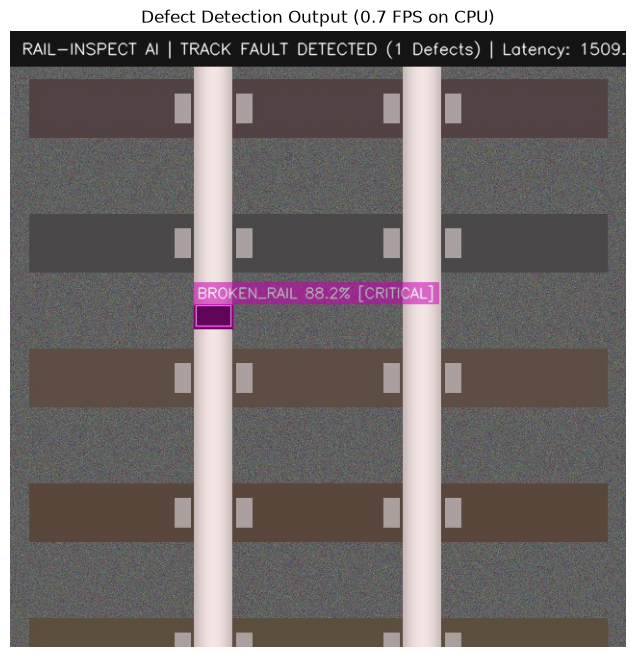

In [2]:
test_img_dir = os.path.join(PROJECT_ROOT, "data/segmentation/images/test")
if os.path.exists(test_img_dir):
    test_files = [f for f in os.listdir(test_img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if test_files:
        sample_path = os.path.join(test_img_dir, test_files[0])
        result = pipeline.predict(sample_path, save_annotated=True)
        
        print(f"Track Condition: {result['status']}")
        print(f"Detected Defect Count: {result['defect_count']}")
        print(f"CPU Latency: {result['cpu_latency_ms']:.1f} ms | FPS: {result['cpu_fps']:.1f}")
        
        annotated_img = cv2.imread(result['annotated_output'])
        plt.figure(figsize=(10, 8))
        plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
        plt.title(f"Defect Detection Output ({result['cpu_fps']:.1f} FPS on CPU)")
        plt.axis("off")
        plt.show()

### 2. Quantitative Performance Evaluation

In [3]:
from segmentation.evaluate_metrics import evaluate_segmentation

data_yaml = os.path.join(PROJECT_ROOT, "data/segmentation/data.yaml")
metrics = evaluate_segmentation(weights=model_weights, data_yaml=data_yaml)

print("\nSummary Performance Metrics:")
print(f"- Box mAP@50:       {metrics['box_map50']:.2f}%")
print(f"- Mask mAP@50:      {metrics['mask_map50']:.2f}%")
print(f"- Mean IoU (mIoU):  {metrics['miou']:.2f}%")
print(f"- Dice Coefficient: {metrics['dice']:.2f}%")
print(f"- CPU Latency:      {metrics['cpu_latency_ms']:.2f} ms")

 Evaluating Railway Defect Localization & Segmentation (CPU)
[*] Model weights: /home/kom/projects/railway/models/railway_yolov8n_seg.pt
Ultralytics 8.4.215 🚀 Python-3.12.3 torch-2.15.0+cpu CPU (12th Gen Intel Core i5-12450H)


YOLOv8n-seg summary (fused): 86 layers, 3,385,852 parameters, 0 gradients, 11.9 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1587.9±421.2 MB/s, size: 155.8 KB)


val: Scanning /home/kom/projects/railway/data/segmentation/labels/val.cache... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 5.0Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 2.9s/it 0.9s<2.9s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.2it/s 1.7s

... (5 outputs left out)

Speed: 1.1ms preprocess, 35.3ms inference, 0.0ms loss, 8.8ms postprocess per image


Results saved to /home/kom/projects/railway/notebooks/runs/segment/val-2



 NEW PROJECT EVALUATION RESULTS: YOLOv8n-seg
  Box mAP@50 (Defect Detection):      99.50%
  Box mAP@50-95:                      85.85%
  Mask mAP@50 (Defect Segmentation):  95.72%
  Mask mAP@50-95:                     45.25%
  Precision:                          98.60%
  Recall:                             93.94%
  Mean IoU (mIoU):                    95.72%
  Dice Coefficient:                   97.81%
  CPU Inference Latency:              35.25 ms per image
  CPU Processing Throughput:          28.4 FPS


[✓] Saved model comparison chart to: /home/kom/projects/railway/docs/images/model_comparison.png

Summary Performance Metrics:
- Box mAP@50:       99.50%
- Mask mAP@50:      95.72%
- Mean IoU (mIoU):  95.72%
- Dice Coefficient: 97.81%
- CPU Latency:      35.25 ms
